### 从感知机到神经网络
感知机的缺点是需要**人工**完成一些工作，比如设定权重，确定的、符合预期的输入输出的权重依旧是人工完成的，效率这一块肯定没有计算机高
所以引入神经网络是为了解决这个问题，自动地学习合适的权重参数

神经网络可以被分为
最左边的：输入层
中间的：中间层（隐藏层hidesuwa）
最右边的：输出层

就神经元的链接方式来看，感知机和神经网络没有任何差异，那么神经网络是怎么自动传递信号呢？

**引入激活函数**
原本感知机的是数学公式
$$y = \begin{cases} 0 & (b + w_1 x_1 + w_2 x_2 \leq 0) \\ 1 & (b + w_1 x_1 + w_2 x_2 > 0) \end{cases}$$

现在引入一个函数h
$$y = h(b + w_1 x_1 + w_2 x_2)$$

h函数（激活函数）会将输入信号的总和转换为输出信号

### 激活函数
使用**阶跃函数**（一旦超过阈值，就切换输出的函数）作为激活函数
#### sigmod 函数
$$h(x) = \frac{1}{1 + e^{-x}}$$

激活函数和感知机主要区别就在于这个激活函数

#### 阶跃函数的实现
超简单：
这种只允许实数，不允许numpy数组

In [ ]:
def step_function(x):
    if x > 0:
        return 1
    else:
        return 0
        


修改为下面，支持numpy实现

In [8]:
def step_function(x):
    y = x > 0
    return y.astype(np.int)

我没理解，我跟着鱼书往下实践

In [1]:
import numpy as np
x = np.array([-1.0, 1.0, 2.0])
x

array([-1.,  1.,  2.])

In [6]:
y = x > 0 
y

array([False,  True,  True])

In [ ]:
y = y.astype(int) # astype()通过参数指定期望的类型，bool -> int 
y

array([0, 1, 1])

#### 接下来来看阶跃函数的图形

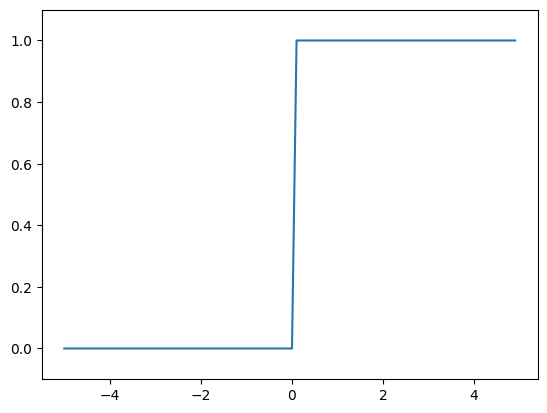

In [11]:
import numpy as np
import matplotlib.pyplot as plt
def step_function(x):
    return np.array(x > 0, dtype=int)

x = np.arange(-5.0, 5.0, 0.1)
y = step_function(x) 
plt.plot(x, y)
plt.ylim(-0.1, 1.1) # 设置y轴的范围
plt.show()

#### sigmod 函数实现

In [12]:
def sigmoid(x):
    return 1 / ( 1 + np.exp(-x))


In [13]:
x = np.array([-1.0, 1.0, 2.0])
sigmoid(x)

array([0.26894142, 0.73105858, 0.88079708])

sigmoid函数支持numpy数据，在于numpy的广播功能，在标量和数组的运算时，标量会和向量的各个元素运算

In [16]:
t = np.array([1.0, 2.0, 3.0])
1.0 + t

array([2., 3., 4.])

In [17]:
1 / t

array([1.        , 0.5       , 0.33333333])

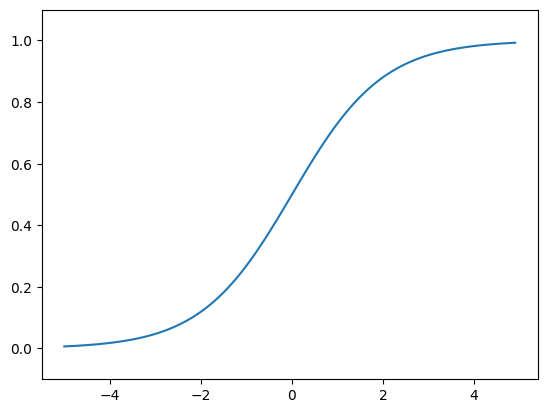

In [19]:
x2 = np.arange(-5.0, 5.0, 0.1)
y2 = sigmoid(x2) 
plt.plot(x2, y2)
plt.ylim(-0.1, 1.1) # 设置y轴的范围
plt.show()

#### sigmoid函数和阶跃函数的比较

“平滑性”：sigmoid的输出是连续的，且在整个定义域内可导。相比于阶跃函数，sigmoid函数的平滑性使得它在训练神经网络时更容易进行梯度下降优化。

#### 非线性函数

sigmoid函数和阶跃函数的相同点：都是非线性函数
神经网络的激活函数必须使用非线性函数
线性函数的问题是不管怎么加深层数，总是存在**等效的**“无隐藏的神经网络”
比如，y(x) = h(h(h(x)))，若h(x)是一个线性函数c，那么y(x) = c^3 x


#### ReLU函数
最新使用的ReLU函数，Rectified Linear Unit函数

$$h(x) = \begin{cases} x & (x > 0) \\ 0 & (x \leq 0) \end{cases}$$


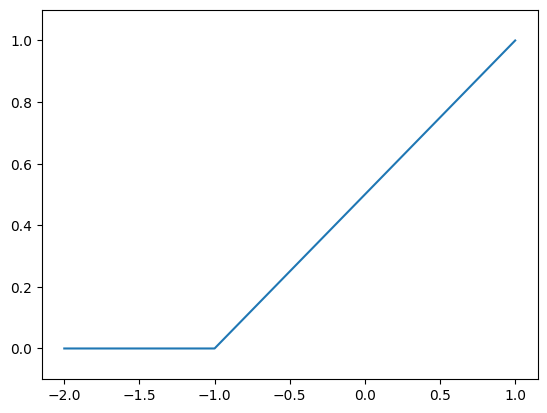

In [25]:
def relu(x):
    return np.maximum(0, x)
x = np.array([- 2.0 ,-1.0,  1.0])
y = relu(x)
plt.plot(x, y)
plt.ylim(-0.1, 1.1) # 设置y轴的范围
plt.show()


### 多维数组运算
简单的说，多维数组就是数字的集合
从一维数组开始

In [28]:
import numpy as np
A = np.array([[1, 2 , 3, 4]])
print(A)
print(np.ndim(A)) # 维度
print(A.shape) # 形状
print(A.shape[0]) # 行数
print(A.shape[1]) # 列数

[[1 2 3 4]]
2
(1, 4)
1
4


二维数组也被称为矩阵

In [29]:
B = np.array([[1, 2], [3, 4], [5, 6]])
print(B)
print(np.ndim(B))
print(B.shape)
print(B.shape[0])
print(B.shape[1])

[[1 2]
 [3 4]
 [5 6]]
2
(3, 2)
3
2


两个矩阵可以通过np.dot()函数计算，返回函数的乘积

In [30]:
A = np.array([[1, 2 , 3], [4, 5 , 6]])
print(A.shape)
B = np.array([[1, 2], [3, 4], [5, 6]])
print(B.shape)
np.dot(A, B) # 矩阵乘法

(2, 3)
(3, 2)


array([[22, 28],
       [49, 64]])

如果形状不能正常匹配，会出现如下错误


In [31]:
C = np.array([[1, 2], [3, 4]])
print(C.shape)
np.dot(A, C) # 矩阵乘法

(2, 2)


ValueError: shapes (2,3) and (2,2) not aligned: 3 (dim 1) != 2 (dim 0)

#### 神经网路的内积
我们已经学习了numpy矩阵的一点内容，下面用numpy实现神经网络
还记得一开始感知机的方程是怎么写的吗？忘记了就回去看看！
（此处省略偏置和激活函数）

$$\begin{pmatrix} x_1 & x_2 \end{pmatrix}
\begin{pmatrix} 1 & 3 & 5 \\ 2 & 4 & 6 \end{pmatrix}
= \begin{pmatrix} y_1 & y_2 & y_3 \end{pmatrix}$$


$$\underbrace{X}_{2} \; \underbrace{W}_{2 \times 3} \; = \; \underbrace{Y}_{3}$$


In [32]:
X = np.array([1,2])
print(X)

W = np.array([[1,3,5],[2,4,6]])
print(W.shape)

Y = np.dot(X, W)
print(Y)

[1 2]
(2, 3)
[ 5 11 17]


### 3层神经网络的实现
来实现以下输入到输出的处理（前向处理）
要记得 y = xw + b
$$w_{\textcolor{red}{1}\textcolor{blue}{2}}^{\textcolor{green}{(1)}}$$

| 部分 | 示例 | 含义 |
|:-----|:-----|:-----|
| **右上角** $(1)$ |🟩绿色 | **层号**：属于第 1 层的权重 |
| **右下角第一个数字** |🟥红色 | **后一层**神经元的索引（第 1 个神经元） |
| **右下角第二个数字** |🟦蓝色 | **前一层**神经元的索引（第 2 个神经元 $x_2$） |

$$\begin{pmatrix} a_1^{(1)} & a_2^{(1)} & a_3^{(1)} \end{pmatrix} = \begin{pmatrix} x_1 & x_2 \end{pmatrix} \begin{pmatrix} w_{11}^{(1)} & w_{21}^{(1)} & w_{31}^{(1)} \\ w_{12}^{(1)} & w_{22}^{(1)} & w_{32}^{(1)} \end{pmatrix} + \begin{pmatrix} b_1^{(1)} & b_2^{(1)} & b_3^{(1)} \end{pmatrix}$$



In [36]:
X = np.array([1.0 , 0.5])
W1 = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
B1 = np.array([0.1, 0.2, 0.3])

print(W1.shape)
print(X.shape)
print(B1.shape)
A1 = np.dot(X, W1) + B1
print(A1)
#加入激活函数
Z1 = sigmoid(A1)
print(Z1)

(2, 3)
(2,)
(3,)
[0.3 0.7 1.1]
[0.57444252 0.66818777 0.75026011]


In [38]:
W2 = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
B2 = np.array([0.1, 0.2])
A2 = np.dot(Z1, W2) + B2
Z2 = sigmoid(A2)

In [40]:
def identity_function(x): # 恒等函数作为激活函数
    return x

W3 = np.array([[0.1, 0.3], [0.2, 0.4]])
B3 = np.array([0.1, 0.2])

A3 = np.dot(Z2, W3) + B3
Y = identity_function(A3)
Y

array([0.31682708, 0.69627909])

#### 神经网络代码小结

In [41]:
def init_network():
    network = {}
    network['W1'] = np.array([[0.1, 0.3, 0.5], [0.2, 0.4, 0.6]])
    network['b1'] = np.array([0.1, 0.2, 0.3])
    network['W2'] = np.array([[0.1, 0.4], [0.2, 0.5], [0.3, 0.6]])
    network['b2'] = np.array([0.1, 0.2])
    network['W3'] = np.array([[0.1, 0.3], [0.2, 0.4]])
    network['b3'] = np.array([0.1, 0.2])
    
    return network
def forward(network, x):
    W1, W2, W3 = network['W1'], network['W2'], network['W3']
    b1, b2, b3 = network['b1'], network['b2'], network['b3']
    
    A1 = np.dot(x, W1) + b1
    Z1 = sigmoid(A1)
    A2 = np.dot(Z1, W2) + b2
    Z2 = sigmoid(A2)
    A3 = np.dot(Z2, W3) + b3
    Y = identity_function(A3)
    
    return Y
network = init_network()
x = np.array([1.0, 0.5])
y = forward(network, x)
y

array([0.31682708, 0.69627909])